In [1]:
# ============================================================
# STEP 8 — LOAD CLEANED DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)

# Load cleaned dataset
df = pd.read_csv("../data/cleaned_healthcare_data.csv")

print("EDA dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

EDA dataset loaded successfully!
Dataset shape: (101766, 46)


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted_30
0,Caucasian,Female,[0-10),6,25,1,1,Unknown,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,Unknown,Unknown,1,Not_Measured,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,0
1,Caucasian,Female,[10-20),1,1,7,3,Unknown,Unknown,59,0,18,0,0,0,276,250.01,255,9,Not_Measured,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0
2,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,Unknown,11,5,13,2,0,1,648,250,V27,6,Not_Measured,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,0
3,Caucasian,Male,[30-40),1,1,7,2,Unknown,Unknown,44,1,16,0,0,0,8,250.43,403,7,Not_Measured,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0
4,Caucasian,Male,[40-50),1,1,7,1,Unknown,Unknown,51,0,8,0,0,0,197,157,250,5,Not_Measured,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,0


Readmission counts:
readmitted_30
0    90409
1    11357
Name: count, dtype: int64

Readmission percentages:
readmitted_30
0    88.84
1    11.16
Name: proportion, dtype: float64


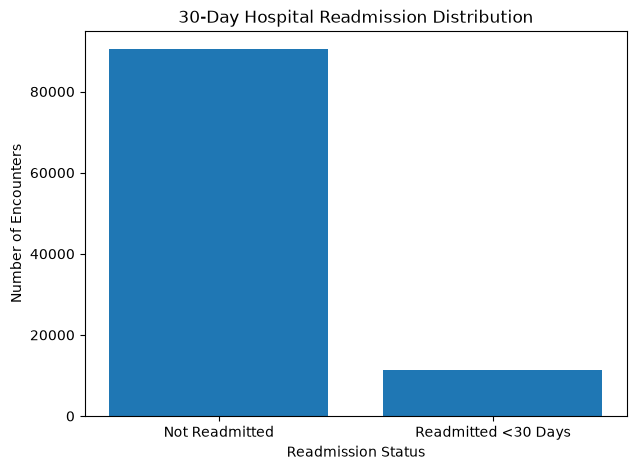

In [2]:
# ============================================================
# STEP 8.2 — 30-DAY READMISSION DISTRIBUTION
# ============================================================

readmission_counts = df["readmitted_30"].value_counts().sort_index()

print("Readmission counts:")
print(readmission_counts)

print("\nReadmission percentages:")
print(
    (df["readmitted_30"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Plot
plt.figure(figsize=(7, 5))

plt.bar(
    ["Not Readmitted", "Readmitted <30 Days"],
    readmission_counts.values
)

plt.title("30-Day Hospital Readmission Distribution")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Encounters")

plt.show()

In [3]:
# ============================================================
# STEP 8.3 — AGE GROUP VS 30-DAY READMISSION
# ============================================================

age_order = [
    "[0-10)",
    "[10-20)",
    "[20-30)",
    "[30-40)",
    "[40-50)",
    "[50-60)",
    "[60-70)",
    "[70-80)",
    "[80-90)",
    "[90-100)"
]

age_analysis = (
    df.groupby("age", observed=False)["readmitted_30"]
      .agg(["count", "mean"])
      .reindex(age_order)
)

age_analysis["readmission_rate"] = (
    age_analysis["mean"] * 100
)

print("Age-wise readmission analysis:")

display(
    age_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

Age-wise readmission analysis:


,count,readmission_rate
age,,
[0-10),161,1.86
[10-20),691,5.79
[20-30),1657,14.24
[30-40),3775,11.23
[40-50),9685,10.60
[50-60),17256,9.67
[60-70),22483,11.13
[70-80),26068,11.77
[80-90),17197,12.08


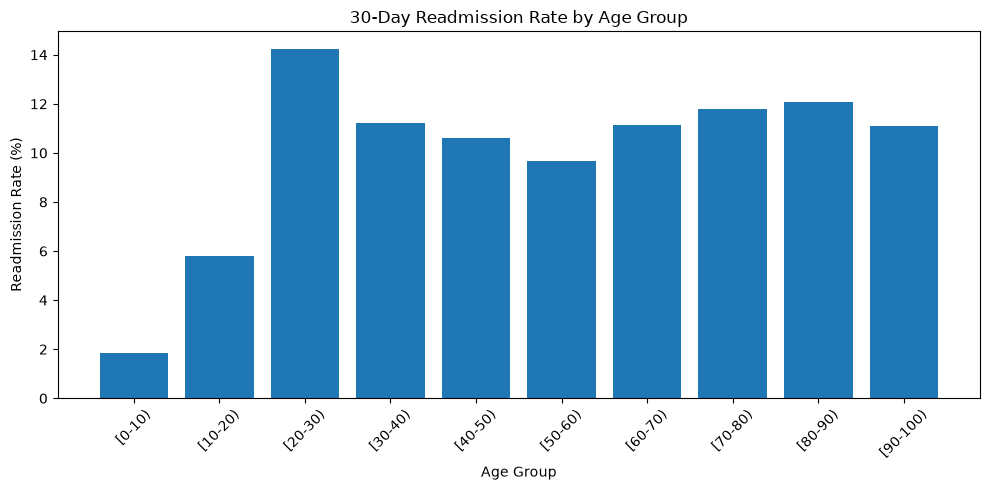

In [4]:
# Age group readmission rate

plt.figure(figsize=(10, 5))

plt.bar(
    age_analysis.index,
    age_analysis["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# STEP 8.4 — PREVIOUS EMERGENCY VISITS VS READMISSION
# ============================================================

emergency_analysis = (
    df.groupby("number_emergency")["readmitted_30"]
      .agg(["count", "mean"])
)

emergency_analysis["readmission_rate"] = (
    emergency_analysis["mean"] * 100
)

display(
    emergency_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
number_emergency,,
0,90383,10.47
1,7677,14.35
2,2042,18.27
3,725,20.28
4,374,30.75
5,192,24.48
6,94,23.40
7,73,26.03
8,50,32.00


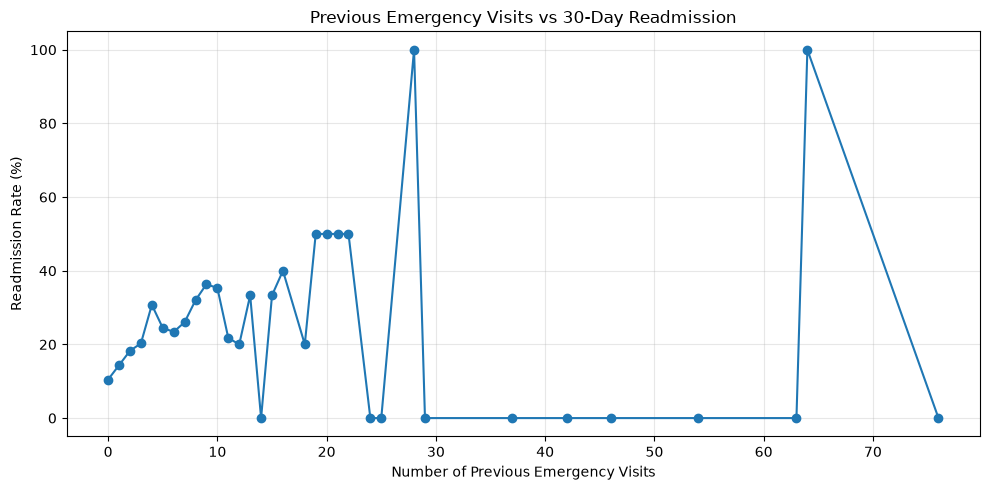

In [6]:
# Previous emergency visits vs 30-day readmission

plt.figure(figsize=(10, 5))

plt.plot(
    emergency_analysis.index,
    emergency_analysis["readmission_rate"],
    marker="o"
)

plt.title("Previous Emergency Visits vs 30-Day Readmission")
plt.xlabel("Number of Previous Emergency Visits")
plt.ylabel("Readmission Rate (%)")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [7]:
# ============================================================
# STEP 8.5 — GROUP PREVIOUS EMERGENCY VISITS
# ============================================================

# Group emergency visits:
# 0, 1, 2, 3, 4, 5+

df["emergency_group"] = pd.cut(
    df["number_emergency"],
    bins=[-1, 0, 1, 2, 3, 4, float("inf")],
    labels=["0", "1", "2", "3", "4", "5+"]
)

emergency_group_analysis = (
    df.groupby("emergency_group", observed=False)["readmitted_30"]
      .agg(["count", "mean"])
)

emergency_group_analysis["readmission_rate"] = (
    emergency_group_analysis["mean"] * 100
)

display(
    emergency_group_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
emergency_group,,
0,90383,10.47
1,7677,14.35
2,2042,18.27
3,725,20.28
4,374,30.75
5+,565,27.08


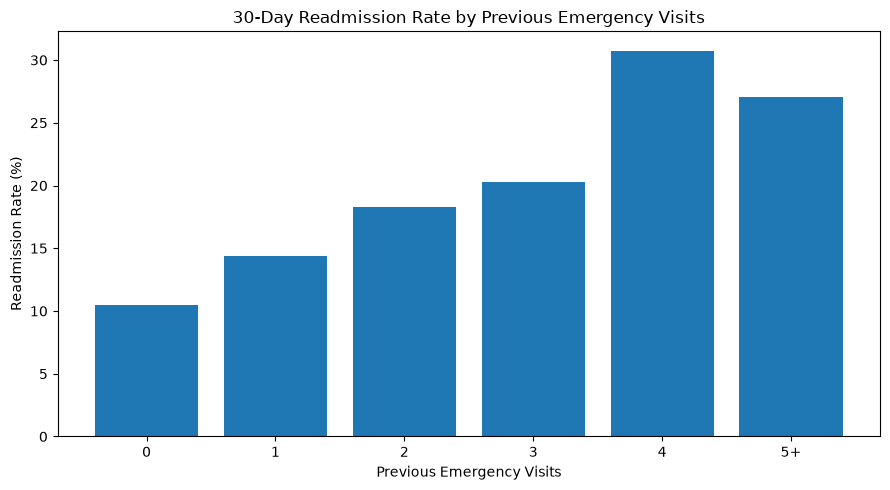

In [8]:
# ============================================================
# PREVIOUS EMERGENCY VISITS VS READMISSION
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    emergency_group_analysis.index.astype(str),
    emergency_group_analysis["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Previous Emergency Visits")
plt.xlabel("Previous Emergency Visits")
plt.ylabel("Readmission Rate (%)")

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# GENDER VS 30-DAY READMISSION
# ============================================================

gender_analysis = (
    df.groupby("gender")["readmitted_30"]
      .agg(["count", "mean"])
)

gender_analysis["readmission_rate"] = (
    gender_analysis["mean"] * 100
)

display(
    gender_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
gender,,
Female,54708,11.25
Male,47055,11.06
Unknown/Invalid,3,0.00


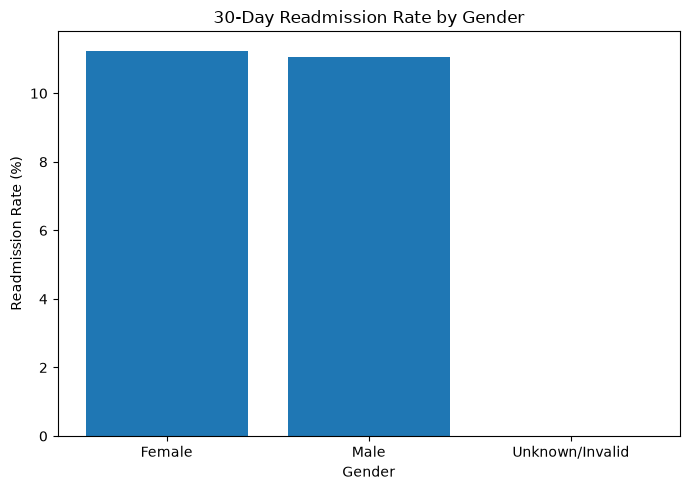

In [10]:
# ============================================================
# GENDER READMISSION RATE
# ============================================================

plt.figure(figsize=(7, 5))

plt.bar(
    gender_analysis.index.astype(str),
    gender_analysis["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Readmission Rate (%)")

plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# RACE VS 30-DAY READMISSION
# ============================================================

race_analysis = (
    df.groupby("race")["readmitted_30"]
      .agg(["count", "mean"])
)

race_analysis["readmission_rate"] = (
    race_analysis["mean"] * 100
)

display(
    race_analysis[
        ["count", "readmission_rate"]
    ]
    .sort_values("count", ascending=False)
    .round(2)
)

,count,readmission_rate
race,,
Caucasian,76099,11.29
AfricanAmerican,19210,11.22
Unknown,2273,8.27
Hispanic,2037,10.41
Other,1506,9.63
Asian,641,10.14


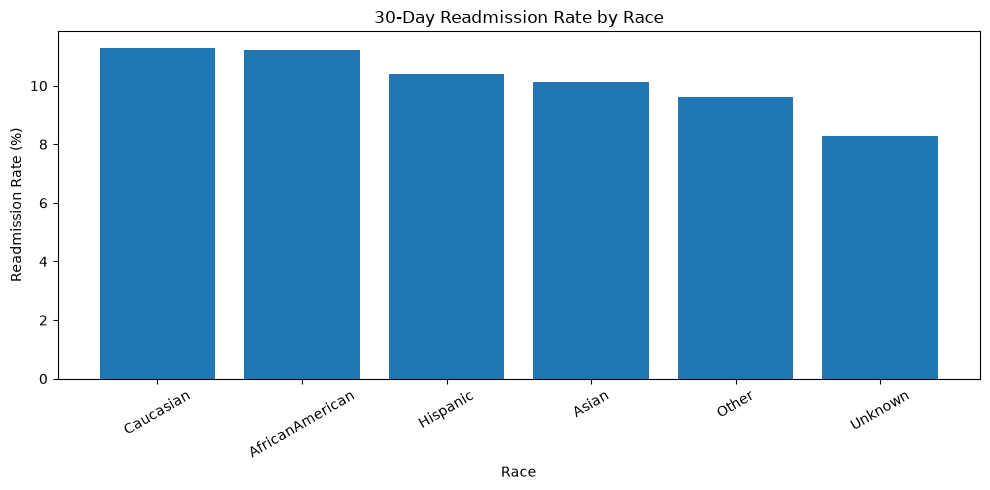

In [12]:
# ============================================================
# RACE READMISSION RATE
# ============================================================

race_plot = (
    race_analysis
    .sort_values("readmission_rate", ascending=False)
)

plt.figure(figsize=(10, 5))

plt.bar(
    race_plot.index.astype(str),
    race_plot["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Race")
plt.xlabel("Race")
plt.ylabel("Readmission Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# TIME IN HOSPITAL VS 30-DAY READMISSION
# ============================================================

hospital_stay_analysis = (
    df.groupby("time_in_hospital")["readmitted_30"]
      .agg(["count", "mean"])
)

hospital_stay_analysis["readmission_rate"] = (
    hospital_stay_analysis["mean"] * 100
)

display(
    hospital_stay_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
time_in_hospital,,
1,14208,8.18
2,17224,9.94
3,17756,10.67
4,13924,11.81
5,9966,12.03
6,7539,12.59
7,5859,12.83
8,4391,14.23
9,3002,13.72


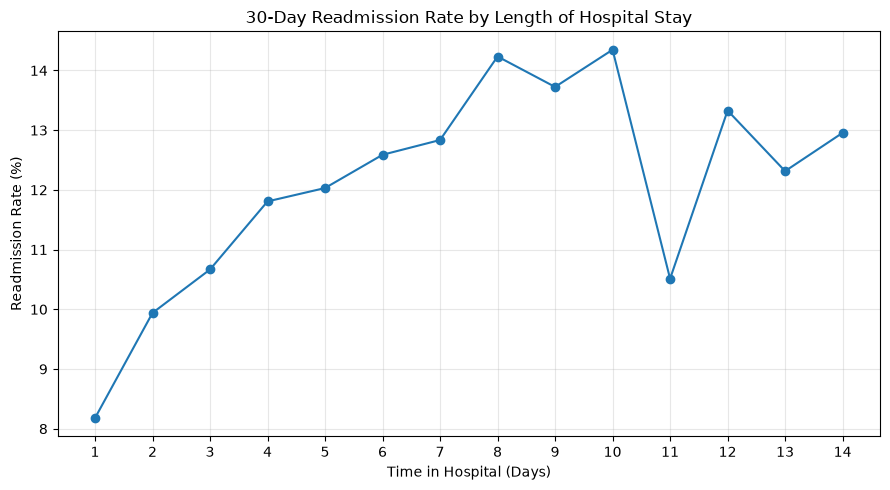

In [14]:
# ============================================================
# HOSPITAL STAY VS READMISSION
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    hospital_stay_analysis.index,
    hospital_stay_analysis["readmission_rate"],
    marker="o"
)

plt.title("30-Day Readmission Rate by Length of Hospital Stay")
plt.xlabel("Time in Hospital (Days)")
plt.ylabel("Readmission Rate (%)")

plt.xticks(hospital_stay_analysis.index)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# SAMPLE SIZE CHECK — TIME IN HOSPITAL
# ============================================================

display(
    hospital_stay_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
time_in_hospital,,
1,14208,8.18
2,17224,9.94
3,17756,10.67
4,13924,11.81
5,9966,12.03
6,7539,12.59
7,5859,12.83
8,4391,14.23
9,3002,13.72


In [16]:
# ============================================================
# PREVIOUS INPATIENT VISITS VS 30-DAY READMISSION
# ============================================================

inpatient_analysis = (
    df.groupby("number_inpatient")["readmitted_30"]
      .agg(["count", "mean"])
)

inpatient_analysis["readmission_rate"] = (
    inpatient_analysis["mean"] * 100
)

display(
    inpatient_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
number_inpatient,,
0,67630,8.44
1,19521,12.92
2,7566,17.43
3,3411,20.29
4,1622,23.61
5,812,31.40
6,480,34.58
7,268,35.45
8,151,44.37


In [17]:
# ============================================================
# GROUP PREVIOUS INPATIENT VISITS
# ============================================================

df["inpatient_group"] = df["number_inpatient"].apply(
    lambda x: str(x) if x < 5 else "5+"
)

inpatient_group_analysis = (
    df.groupby("inpatient_group", observed=False)["readmitted_30"]
      .agg(["count", "mean"])
)

inpatient_group_analysis["readmission_rate"] = (
    inpatient_group_analysis["mean"] * 100
)

# Correct ordering
inpatient_order = ["0", "1", "2", "3", "4", "5+"]

inpatient_group_analysis = (
    inpatient_group_analysis
    .reindex(inpatient_order)
)

display(
    inpatient_group_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
inpatient_group,,
0,67630,8.44
1,19521,12.92
2,7566,17.43
3,3411,20.29
4,1622,23.61
5+,2016,36.41


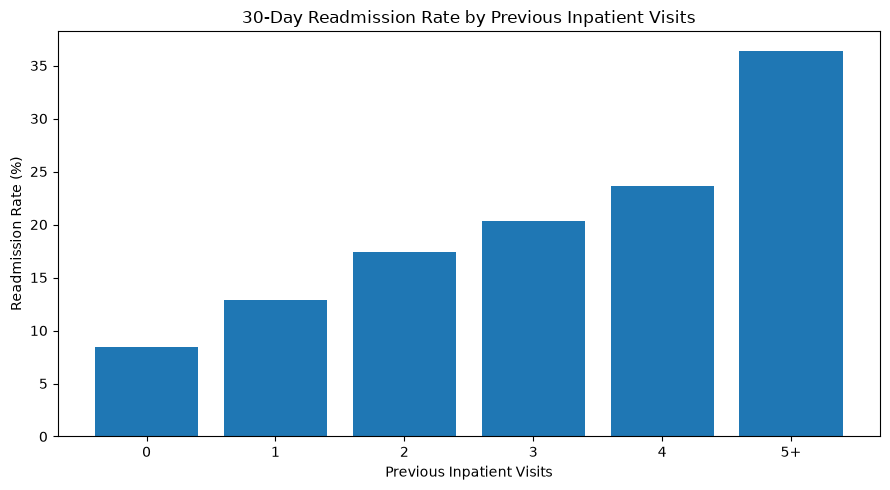

In [18]:
# ============================================================
# 30-DAY READMISSION RATE BY PREVIOUS INPATIENT VISITS
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    inpatient_group_analysis.index,
    inpatient_group_analysis["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Previous Inpatient Visits")
plt.xlabel("Previous Inpatient Visits")
plt.ylabel("Readmission Rate (%)")

plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# NUMBER OF DIAGNOSES VS 30-DAY READMISSION
# ============================================================

diagnosis_analysis = (
    df.groupby("number_diagnoses")["readmitted_30"]
      .agg(["count", "mean"])
)

diagnosis_analysis["readmission_rate"] = (
    diagnosis_analysis["mean"] * 100
)

display(
    diagnosis_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
number_diagnoses,,
1,219,5.94
2,1023,6.06
3,2835,7.37
4,5537,8.25
5,11393,9.15
6,10161,10.41
7,10393,10.77
8,10616,11.81
9,49474,12.38


In [20]:
# ============================================================
# GROUP NUMBER OF DIAGNOSES
# ============================================================

df["diagnosis_group"] = df["number_diagnoses"].apply(
    lambda x: str(x) if x <= 9 else "10+"
)

diagnosis_group_analysis = (
    df.groupby("diagnosis_group", observed=False)["readmitted_30"]
      .agg(["count", "mean"])
)

diagnosis_group_analysis["readmission_rate"] = (
    diagnosis_group_analysis["mean"] * 100
)

diagnosis_order = [
    "1", "2", "3", "4", "5",
    "6", "7", "8", "9", "10+"
]

diagnosis_group_analysis = (
    diagnosis_group_analysis
    .reindex(diagnosis_order)
)

display(
    diagnosis_group_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
diagnosis_group,,
1,219,5.94
2,1023,6.06
3,2835,7.37
4,5537,8.25
5,11393,9.15
6,10161,10.41
7,10393,10.77
8,10616,11.81
9,49474,12.38


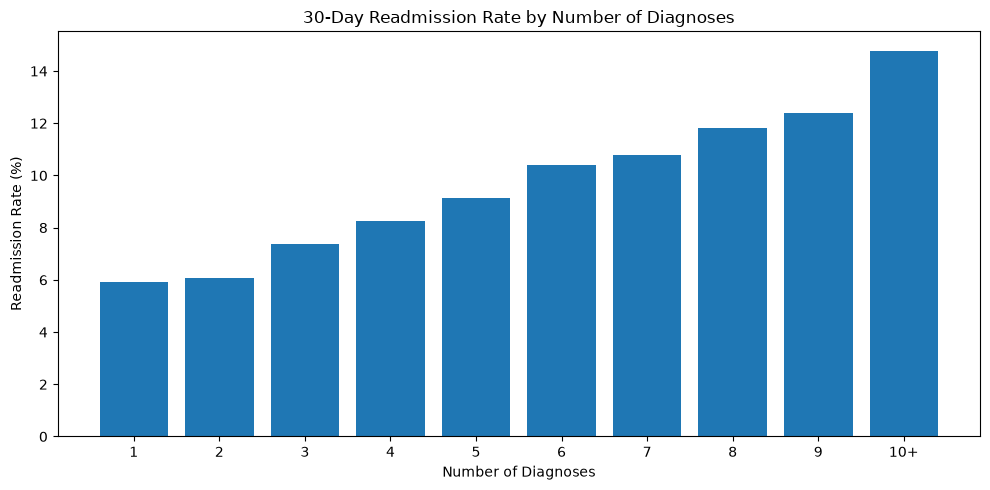

In [21]:
# ============================================================
# 30-DAY READMISSION RATE BY NUMBER OF DIAGNOSES
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    diagnosis_group_analysis.index,
    diagnosis_group_analysis["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Number of Diagnoses")
plt.xlabel("Number of Diagnoses")
plt.ylabel("Readmission Rate (%)")

plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# NUMBER OF MEDICATIONS VS 30-DAY READMISSION
# ============================================================

medication_analysis = (
    df.groupby("num_medications")["readmitted_30"]
      .agg(["count", "mean"])
)

medication_analysis["readmission_rate"] = (
    medication_analysis["mean"] * 100
)

display(
    medication_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
num_medications,,
1,262,4.20
2,470,8.30
3,900,7.22
4,1417,8.05
5,2017,7.44
...,...,...
72,3,100.00
74,1,0.00
75,2,0.00


In [23]:
# ============================================================
# MEDICATION GROUP vs 30-DAY READMISSION
# ============================================================

df["medication_group"] = pd.cut(
    df["num_medications"],
    bins=[0, 5, 10, 15, 20, 30, float("inf")],
    labels=["1-5", "6-10", "11-15", "16-20", "21-30", "31+"]
)

medication_group_analysis = (
    df.groupby("medication_group", observed=False)["readmitted_30"]
      .agg(["count", "mean"])
)

medication_group_analysis["readmission_rate"] = (
    medication_group_analysis["mean"] * 100
)

display(
    medication_group_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
medication_group,,
1-5,5066,7.48
6-10,20795,9.45
11-15,29384,10.91
16-20,22641,12.17
21-30,18643,12.87
31+,5237,12.43


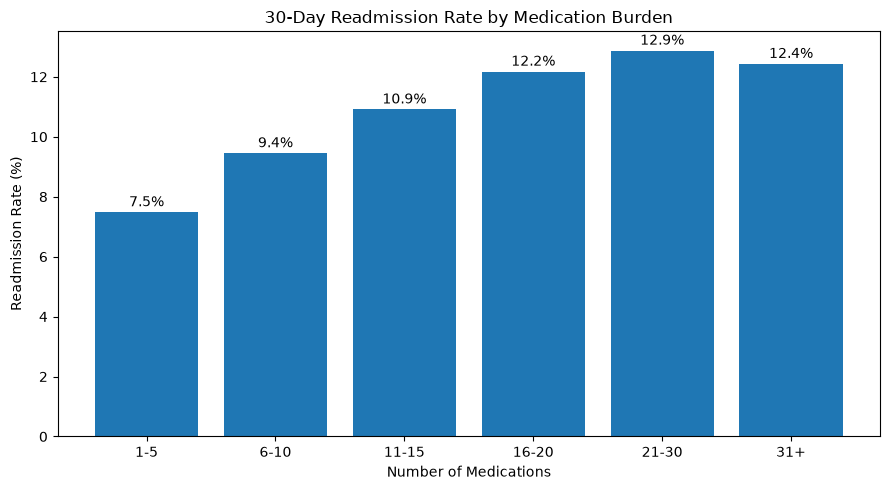

In [24]:
# ============================================================
# MEDICATION BURDEN vs 30-DAY READMISSION
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    medication_group_analysis.index.astype(str),
    medication_group_analysis["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Medication Burden")
plt.xlabel("Number of Medications")
plt.ylabel("Readmission Rate (%)")

# Add percentage labels
for i, value in enumerate(
    medication_group_analysis["readmission_rate"]
):
    plt.text(
        i,
        value + 0.2,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [25]:
# ============================================================
# DIABETES-RELATED COLUMNS
# ============================================================

diabetes_cols = [
    col for col in df.columns
    if "diabet" in col.lower()
]

print("Diabetes-related columns:")
for col in diabetes_cols:
    print("-", col)

Diabetes-related columns:
- diabetesMed


In [26]:
# Show unique values for diabetes-related columns
for col in diabetes_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))


--- diabetesMed ---
diabetesMed
Yes    78363
No     23403
Name: count, dtype: int64


In [27]:
# ============================================================
# DIABETES MEDICATION vs 30-DAY READMISSION
# ============================================================

diabetes_analysis = (
    df.groupby("diabetesMed")["readmitted_30"]
      .agg(["count", "mean"])
)

diabetes_analysis["readmission_rate"] = (
    diabetes_analysis["mean"] * 100
)

display(
    diabetes_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
diabetesMed,,
No,23403,9.60
Yes,78363,11.63


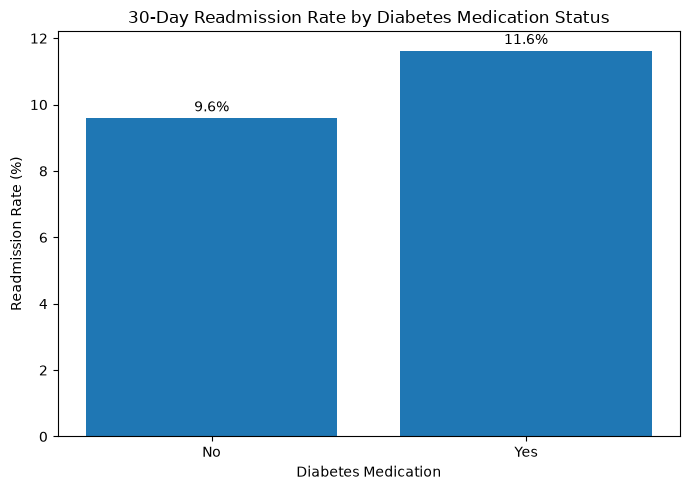

In [28]:
# ============================================================
# DIABETES MEDICATION READMISSION RATE
# ============================================================

plt.figure(figsize=(7, 5))

plt.bar(
    diabetes_analysis.index.astype(str),
    diabetes_analysis["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Diabetes Medication Status")
plt.xlabel("Diabetes Medication")
plt.ylabel("Readmission Rate (%)")

for i, value in enumerate(
    diabetes_analysis["readmission_rate"]
):
    plt.text(
        i,
        value + 0.2,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [29]:
# ============================================================
# ENCOUNTER / ADMISSION RELATED COLUMNS
# ============================================================

encounter_cols = [
    col for col in df.columns
    if any(x in col.lower() for x in [
        "admission",
        "discharge",
        "encounter",
        "source",
        "type"
    ])
]

print("Encounter/admission-related columns:")
for col in encounter_cols:
    print("-", col)

Encounter/admission-related columns:
- admission_type_id
- discharge_disposition_id
- admission_source_id


In [30]:
for col in encounter_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))


--- admission_type_id ---
admission_type_id
1    53990
3    18869
2    18480
6     5291
5     4785
8      320
7       21
4       10
Name: count, dtype: int64

--- discharge_disposition_id ---
discharge_disposition_id
1     60234
3     13954
6     12902
18     3691
2      2128
22     1993
11     1642
5      1184
25      989
4       815
7       623
23      412
13      399
14      372
28      139
Name: count, dtype: int64

--- admission_source_id ---
admission_source_id
7     57494
1     29565
17     6781
4      3187
6      2264
2      1104
5       855
3       187
20      161
9       125
8        16
22       12
10        8
14        2
11        2
Name: count, dtype: int64


In [31]:
# ============================================================
# ADMISSION TYPE vs 30-DAY READMISSION
# ============================================================

admission_analysis = (
    df.groupby("admission_type_id")["readmitted_30"]
      .agg(["count", "mean"])
)

admission_analysis["readmission_rate"] = (
    admission_analysis["mean"] * 100
)

display(
    admission_analysis[
        ["count", "readmission_rate"]
    ]
    .sort_values("count", ascending=False)
    .round(2)
)

,count,readmission_rate
admission_type_id,,
1,53990,11.52
3,18869,10.39
2,18480,11.18
6,5291,11.08
5,4785,10.34
8,320,8.44
7,21,0.00
4,10,10.00


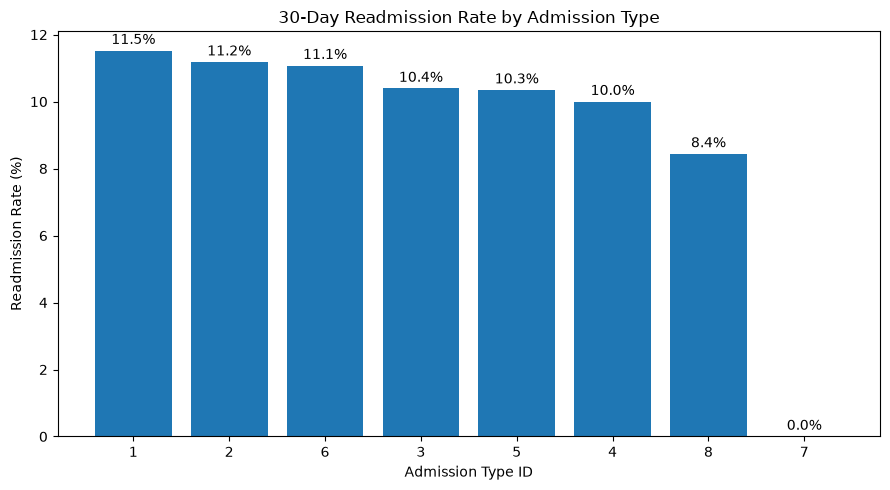

In [32]:
# ============================================================
# ADMISSION TYPE READMISSION RATE
# ============================================================

admission_plot = (
    admission_analysis
    .sort_values("readmission_rate", ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    admission_plot.index.astype(str),
    admission_plot["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Admission Type")
plt.xlabel("Admission Type ID")
plt.ylabel("Readmission Rate (%)")

for i, value in enumerate(
    admission_plot["readmission_rate"]
):
    plt.text(
        i,
        value + 0.2,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [33]:
admission_type_map = {
    1: "Emergency",
    2: "Urgent",
    3: "Elective",
    4: "Newborn",
    5: "Not Available",
    6: "NULL / Unknown",
    7: "Trauma Center",
    8: "Not Mapped"
}

admission_analysis["admission_type"] = (
    admission_analysis.index.map(admission_type_map)
)

display(
    admission_analysis[
        ["admission_type", "count", "readmission_rate"]
    ]
    .sort_values("count", ascending=False)
    .round(2)
)

,admission_type,count,readmission_rate
admission_type_id,,,
1,Emergency,53990,11.52
3,Elective,18869,10.39
2,Urgent,18480,11.18
6,NULL / Unknown,5291,11.08
5,Not Available,4785,10.34
8,Not Mapped,320,8.44
7,Trauma Center,21,0.00
4,Newborn,10,10.00


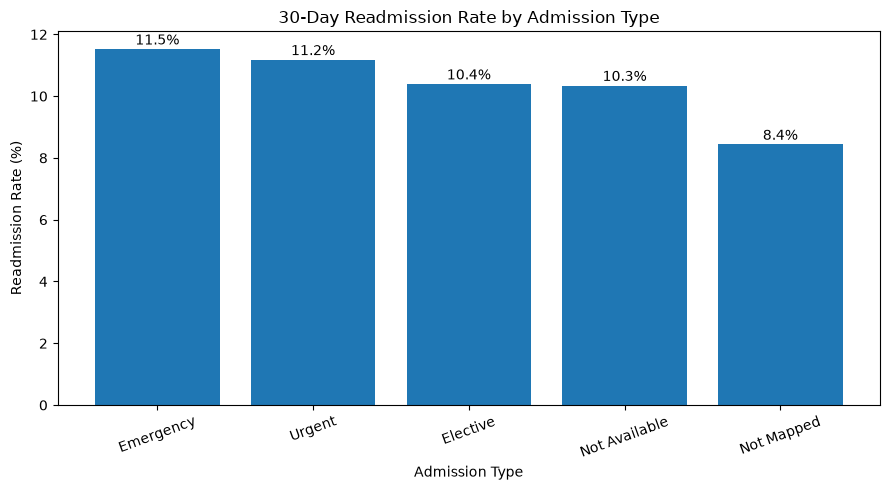

In [34]:
# ============================================================
# CLEAN ADMISSION TYPE ANALYSIS
# ============================================================

main_admission_types = [1, 2, 3, 5, 8]

admission_plot = (
    admission_analysis
    .loc[admission_analysis.index.isin(main_admission_types)]
    .sort_values("readmission_rate", ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    admission_plot["admission_type"],
    admission_plot["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Readmission Rate (%)")

for i, value in enumerate(
    admission_plot["readmission_rate"]
):
    plt.text(
        i,
        value + 0.15,
        f"{value:.1f}%",
        ha="center"
    )

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [35]:
# ============================================================
# DISCHARGE DISPOSITION vs 30-DAY READMISSION
# ============================================================

# Check frequency of each discharge disposition
discharge_counts = df["discharge_disposition_id"].value_counts().sort_index()

display(discharge_counts)

discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64

In [36]:
# ============================================================
# GROUP RARE DISCHARGE DISPOSITIONS
# ============================================================

discharge_counts = df["discharge_disposition_id"].value_counts()

# Keep categories with at least 500 patients
common_dispositions = discharge_counts[
    discharge_counts >= 500
].index

df["discharge_group"] = df["discharge_disposition_id"].apply(
    lambda x: str(int(x)) if x in common_dispositions else "Other/Rare"
)

print("Discharge groups:")
print(df["discharge_group"].value_counts())

Discharge groups:
discharge_group
1             60234
3             13954
6             12902
18             3691
2              2128
22             1993
11             1642
Other/Rare     1611
5              1184
25              989
4               815
7               623
Name: count, dtype: int64


In [37]:
# ============================================================
# DISCHARGE GROUP vs 30-DAY READMISSION
# ============================================================

discharge_analysis = (
    df.groupby("discharge_group", observed=False)["readmitted_30"]
      .agg(["count", "mean"])
)

discharge_analysis["readmission_rate"] = (
    discharge_analysis["mean"] * 100
)

display(
    discharge_analysis[
        ["count", "readmission_rate"]
    ]
    .sort_values("readmission_rate", ascending=False)
    .round(2)
)

,count,readmission_rate
discharge_group,,
22,1993,27.70
5,1184,20.86
2,2128,16.07
3,13954,14.66
7,623,14.45
4,815,12.76
6,12902,12.70
18,3691,12.44
Other/Rare,1611,11.48


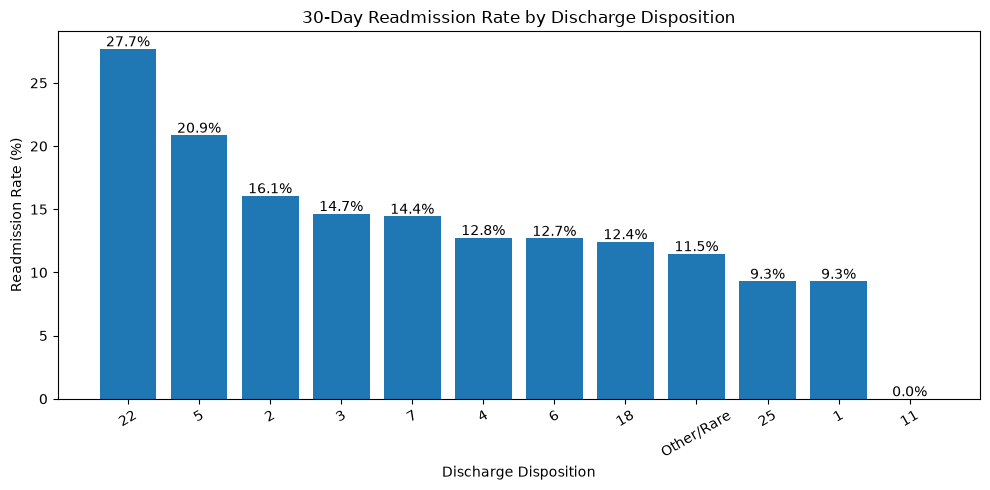

In [38]:
# ============================================================
# DISCHARGE DISPOSITION READMISSION RATE
# ============================================================

discharge_plot = (
    discharge_analysis
    .sort_values("readmission_rate", ascending=False)
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    discharge_plot.index.astype(str),
    discharge_plot["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Discharge Disposition")
plt.xlabel("Discharge Disposition")
plt.ylabel("Readmission Rate (%)")

# Add percentage labels
for bar, value in zip(
    bars,
    discharge_plot["readmission_rate"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{value:.1f}%",
        ha="center"
    )

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [39]:
# ============================================================
# MAP DISCHARGE DISPOSITION IDS TO MEANINGFUL LABELS
# ============================================================

discharge_mapping = {
    1: "Home",
    2: "Short-term Hospital",
    3: "Skilled Nursing Facility",
    4: "Intermediate Care Facility",
    5: "Other Inpatient Facility",
    6: "Home Health",
    7: "Left Against Medical Advice",
    8: "Home IV Provider",
    9: "Inpatient Hospice",
    10: "Hospice",
    11: "Expired",
    12: "Still Patient",
    13: "Home",
    14: "Hospice",
    15: "Other",
    16: "Other",
    17: "Other",
    18: "Other",
    19: "Other",
    20: "Other",
    21: "Other",
    22: "Rehabilitation Facility",
    23: "Long-term Care Hospital",
    24: "Other",
    25: "Not Mapped",
    26: "Unknown",
    27: "Other",
    28: "Other",
    29: "Other",
    30: "Other"
}

df["discharge_label"] = (
    df["discharge_disposition_id"]
    .map(discharge_mapping)
    .fillna("Unknown")
)

display(
    df[
        ["discharge_disposition_id", "discharge_label"]
    ].drop_duplicates()
    .sort_values("discharge_disposition_id")
)

,discharge_disposition_id,discharge_label
1,1,Home
29,2,Short-term Hospital
9,3,Skilled Nursing Facility
972,4,Intermediate Care Facility
31,5,Other Inpatient Facility
13,6,Home Health
82,7,Left Against Medical Advice
3558,8,Home IV Provider
16783,9,Inpatient Hospice
487,10,Hospice


In [40]:
# ============================================================
# CLINICAL DISCHARGE GROUPS
# ============================================================

clinical_discharge_mapping = {
    1: "Home",
    2: "Short-term Hospital",
    3: "Skilled Nursing Facility",
    4: "Intermediate Care Facility",
    5: "Other Inpatient Care",
    6: "Home Health",
    7: "Left Against Medical Advice",
    8: "Home IV Provider",
    9: "Hospice",
    10: "Hospice",
    11: "Expired",
    12: "Still Patient",
    13: "Home",
    14: "Hospice",
    15: "Other",
    16: "Other",
    17: "Other",
    18: "Other",
    19: "Other",
    20: "Other",
    21: "Other",
    22: "Rehabilitation Facility",
    23: "Long-term Care Hospital",
    24: "Other",
    25: "Not Mapped",
    26: "Unknown",
    27: "Other",
    28: "Other",
    29: "Other",
    30: "Other"
}

df["clinical_discharge_group"] = (
    df["discharge_disposition_id"]
    .map(clinical_discharge_mapping)
    .fillna("Unknown")
)

display(
    df["clinical_discharge_group"]
    .value_counts()
)

clinical_discharge_group
Home                           60633
Skilled Nursing Facility       13954
Home Health                    12902
Other                           3981
Short-term Hospital             2128
Rehabilitation Facility         1993
Expired                         1642
Other Inpatient Care            1184
Not Mapped                       989
Intermediate Care Facility       815
Left Against Medical Advice      623
Long-term Care Hospital          412
Hospice                          399
Home IV Provider                 108
Still Patient                      3
Name: count, dtype: int64

In [41]:
# ============================================================
# READMISSION RATE BY CLINICAL DISCHARGE GROUP
# ============================================================

clinical_discharge_analysis = (
    df.groupby("clinical_discharge_group", observed=False)["readmitted_30"]
      .agg(["count", "mean"])
)

clinical_discharge_analysis["readmission_rate"] = (
    clinical_discharge_analysis["mean"] * 100
)

display(
    clinical_discharge_analysis[
        ["count", "readmission_rate"]
    ]
    .sort_values("count", ascending=False)
    .round(2)
)

,count,readmission_rate
clinical_discharge_group,,
Home,60633,9.27
Skilled Nursing Facility,13954,14.66
Home Health,12902,12.70
Other,3981,13.69
Short-term Hospital,2128,16.07
Rehabilitation Facility,1993,27.70
Expired,1642,0.00
Other Inpatient Care,1184,20.86
Not Mapped,989,9.30


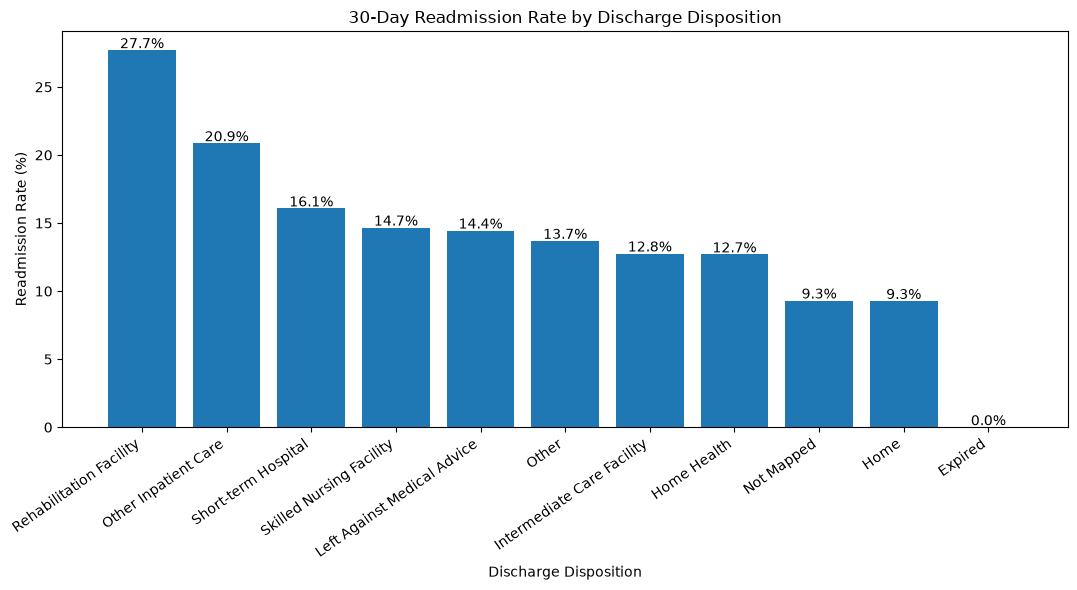

In [42]:
# ============================================================
# FINAL DISCHARGE DISPOSITION CHART
# ============================================================

plot_data = (
    clinical_discharge_analysis[
        clinical_discharge_analysis["count"] >= 500
    ]
    .sort_values("readmission_rate", ascending=False)
)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    plot_data.index,
    plot_data["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Discharge Disposition")
plt.xlabel("Discharge Disposition")
plt.ylabel("Readmission Rate (%)")

for bar, value in zip(
    bars,
    plot_data["readmission_rate"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{value:.1f}%",
        ha="center"
    )

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# ADMISSION SOURCE ANALYSIS
# ============================================================

admission_source_counts = (
    df["admission_source_id"]
    .value_counts()
    .sort_index()
)

display(admission_source_counts)

admission_source_id
1     29565
2      1104
3       187
4      3187
5       855
6      2264
7     57494
8        16
9       125
10        8
11        2
13        1
14        2
17     6781
20      161
22       12
25        2
Name: count, dtype: int64

In [44]:
# ============================================================
# GROUP ADMISSION SOURCES
# ============================================================

admission_source_counts = df["admission_source_id"].value_counts()

# Keep only sufficiently large categories
common_sources = admission_source_counts[
    admission_source_counts >= 500
].index

df["admission_source_group"] = df["admission_source_id"].apply(
    lambda x: str(int(x)) if x in common_sources else "Other/Rare"
)

display(
    df["admission_source_group"]
    .value_counts()
)

admission_source_group
7             57494
1             29565
17             6781
4              3187
6              2264
2              1104
5               855
Other/Rare      516
Name: count, dtype: int64

In [45]:
# ============================================================
# ADMISSION SOURCE vs 30-DAY READMISSION
# ============================================================

admission_source_analysis = (
    df.groupby(
        "admission_source_group",
        observed=False
    )["readmitted_30"]
    .agg(["count", "mean"])
)

admission_source_analysis["readmission_rate"] = (
    admission_source_analysis["mean"] * 100
)

display(
    admission_source_analysis[
        ["count", "readmission_rate"]
    ]
    .sort_values("readmission_rate", ascending=False)
    .round(2)
)

,count,readmission_rate
admission_source_group,,
Other/Rare,516,13.18
5,855,11.81
7,57494,11.69
1,29565,10.59
17,6781,10.41
2,1104,10.05
4,3187,9.70
6,2264,9.36


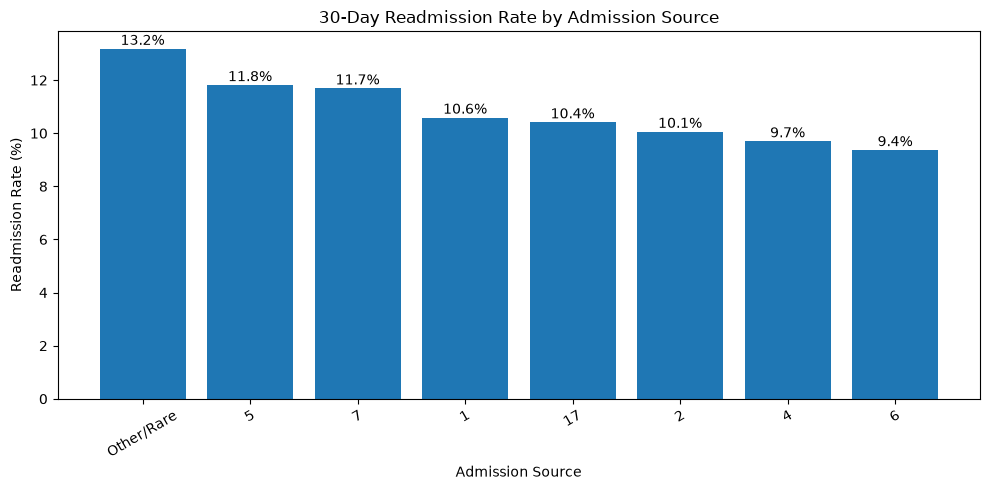

In [46]:
# ============================================================
# ADMISSION SOURCE READMISSION RATE
# ============================================================

source_plot = (
    admission_source_analysis
    .sort_values("readmission_rate", ascending=False)
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    source_plot.index.astype(str),
    source_plot["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Admission Source")
plt.xlabel("Admission Source")
plt.ylabel("Readmission Rate (%)")

for bar, value in zip(
    bars,
    source_plot["readmission_rate"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{value:.1f}%",
        ha="center"
    )

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [47]:
# Check admission source ID mapping if available
display(
    df[["admission_source_id"]]
    .drop_duplicates()
    .sort_values("admission_source_id")
)

,admission_source_id
0,1
5,2
1014,3
8,4
335,5
396,6
1,7
1595,8
24884,9
44582,10


In [48]:
# ============================================================
# ADMISSION SOURCE ID -> MEANINGFUL LABELS
# ============================================================

admission_source_map = {
    1: "Physician Referral",
    2: "Clinic Referral",
    3: "HMO Referral",
    4: "Hospital Transfer",
    5: "Skilled Nursing Facility",
    6: "Other Healthcare Facility",
    7: "Emergency Room",
    8: "Court/Law Enforcement",
    9: "Not Available",
    10: "Critical Access Hospital",
    11: "Normal Delivery",
    13: "Sick Baby",
    14: "Extramural Birth",
    17: "Unknown/Not Specified",
    20: "Not Mapped",
    22: "Hospital Transfer",
    25: "Not Mapped"
}

# Create readable source labels
df["admission_source_label"] = (
    df["admission_source_id"]
    .map(admission_source_map)
    .fillna("Other/Rare")
)

# Check mapping
display(
    df[["admission_source_id", "admission_source_label"]]
    .drop_duplicates()
    .sort_values("admission_source_id")
)

,admission_source_id,admission_source_label
0,1,Physician Referral
5,2,Clinic Referral
1014,3,HMO Referral
8,4,Hospital Transfer
335,5,Skilled Nursing Facility
396,6,Other Healthcare Facility
1,7,Emergency Room
1595,8,Court/Law Enforcement
24884,9,Not Available
44582,10,Critical Access Hospital


In [49]:
# ============================================================
# ADMISSION SOURCE vs 30-DAY READMISSION
# ============================================================

admission_source_analysis = (
    df.groupby("admission_source_label")["readmitted_30"]
    .agg(["count", "mean"])
)

admission_source_analysis["readmission_rate"] = (
    admission_source_analysis["mean"] * 100
)

# Keep categories with at least 500 patients
# to avoid unstable rates from very small samples
admission_source_plot = (
    admission_source_analysis[
        admission_source_analysis["count"] >= 500
    ]
    .sort_values("readmission_rate", ascending=False)
)

display(
    admission_source_plot[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
admission_source_label,,
Skilled Nursing Facility,855,11.81
Emergency Room,57494,11.69
Physician Referral,29565,10.59
Unknown/Not Specified,6781,10.41
Clinic Referral,1104,10.05
Hospital Transfer,3199,9.72
Other Healthcare Facility,2264,9.36


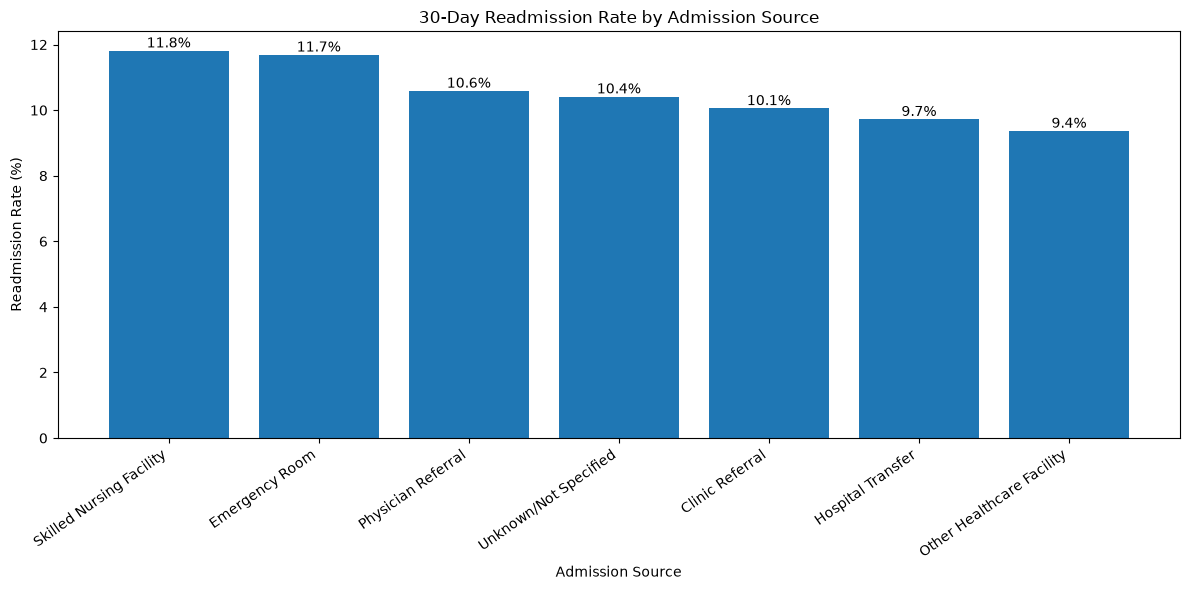

In [50]:
plt.figure(figsize=(12, 6))

bars = plt.bar(
    admission_source_plot.index,
    admission_source_plot["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Admission Source")
plt.xlabel("Admission Source")
plt.ylabel("Readmission Rate (%)")

plt.xticks(rotation=35, ha="right")

# Add percentage labels
for bar, value in zip(
    bars,
    admission_source_plot["readmission_rate"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [51]:
# ============================================================
# CORRECT ADMISSION SOURCE MAPPING
# ============================================================

admission_source_map = {
    1: "Physician Referral",
    2: "Clinic Referral",
    3: "HMO Referral",
    4: "Transfer from Hospital",
    5: "Transfer from Skilled Nursing Facility",
    6: "Transfer from Healthcare Facility",
    7: "Emergency Room",
    8: "Court/Law Enforcement",
    9: "Not Available",
    10: "Critical Access Hospital",
    11: "Normal Delivery",
    13: "Sick Baby",
    14: "Extramural Birth",
    17: "Unknown/Not Specified",
    20: "Not Mapped",
    22: "Transfer from Hospital",
    25: "Not Mapped"
}

df["admission_source_label"] = (
    df["admission_source_id"]
    .map(admission_source_map)
    .fillna("Other/Rare")
)

# Recalculate analysis
admission_source_analysis = (
    df.groupby("admission_source_label")["readmitted_30"]
    .agg(["count", "mean"])
)

admission_source_analysis["readmission_rate"] = (
    admission_source_analysis["mean"] * 100
)

admission_source_plot = (
    admission_source_analysis[
        admission_source_analysis["count"] >= 500
    ]
    .sort_values("readmission_rate", ascending=False)
)

display(
    admission_source_plot[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
admission_source_label,,
Transfer from Skilled Nursing Facility,855,11.81
Emergency Room,57494,11.69
Physician Referral,29565,10.59
Unknown/Not Specified,6781,10.41
Clinic Referral,1104,10.05
Transfer from Hospital,3199,9.72
Transfer from Healthcare Facility,2264,9.36


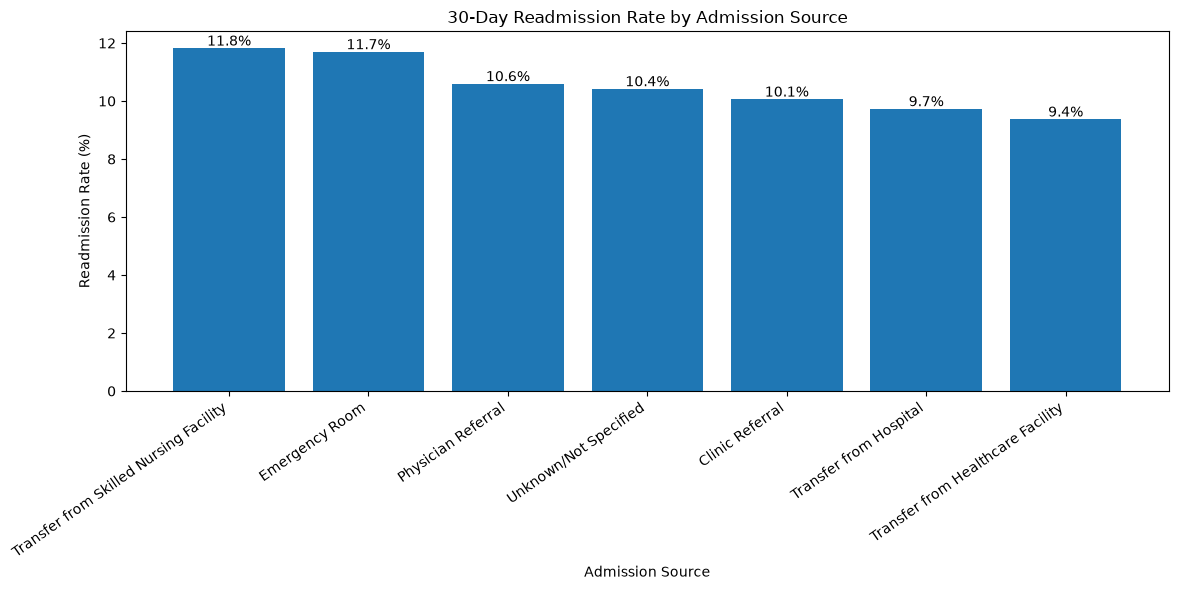

In [52]:
plt.figure(figsize=(12, 6))

bars = plt.bar(
    admission_source_plot.index,
    admission_source_plot["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Admission Source")
plt.xlabel("Admission Source")
plt.ylabel("Readmission Rate (%)")

plt.xticks(rotation=35, ha="right")

for bar, value in zip(
    bars,
    admission_source_plot["readmission_rate"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [53]:
# ============================================================
# AGE GROUP vs 30-DAY READMISSION
# ============================================================

age_bins = [
    0, 30, 40, 50, 60, 70, 80, float("inf")
]

age_labels = [
    "<30",
    "30-39",
    "40-49",
    "50-59",
    "60-69",
    "70-79",
    "80+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_analysis = (
    df.groupby("age_group", observed=False)["readmitted_30"]
    .agg(["count", "mean"])
)

age_analysis["readmission_rate"] = (
    age_analysis["mean"] * 100
)

display(
    age_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

TypeError: '<' not supported between instances of 'float' and 'str'

In [57]:
# ============================================================
# AGE GROUP vs 30-DAY READMISSION
# ============================================================

# Age is already stored as age ranges such as [0-10), [10-20), etc.
age_order = [
    "[0-10)",
    "[10-20)",
    "[20-30)",
    "[30-40)",
    "[40-50)",
    "[50-60)",
    "[60-70)",
    "[70-80)",
    "[80-90)",
    "[90-100)"
]

# Convert age into ordered categorical variable
df["age_group"] = pd.Categorical(
    df["age"],
    categories=age_order,
    ordered=True
)

# Calculate readmission rate
age_analysis = (
    df.groupby("age_group", observed=False)["readmitted_30"]
    .agg(["count", "mean"])
)

age_analysis["readmission_rate"] = (
    age_analysis["mean"] * 100
)

display(
    age_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
age_group,,
[0-10),161,1.86
[10-20),691,5.79
[20-30),1657,14.24
[30-40),3775,11.23
[40-50),9685,10.60
[50-60),17256,9.67
[60-70),22483,11.13
[70-80),26068,11.77
[80-90),17197,12.08


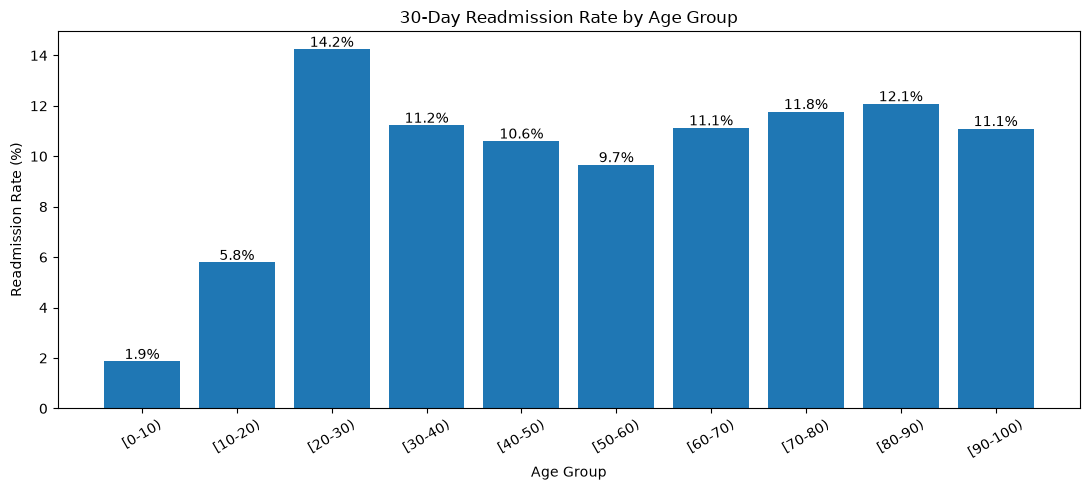

In [58]:
# ============================================================
# AGE GROUP READMISSION RATE
# ============================================================

age_plot = age_analysis.dropna(
    subset=["readmission_rate"]
)

plt.figure(figsize=(11, 5))

bars = plt.bar(
    age_plot.index.astype(str),
    age_plot["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")

plt.xticks(rotation=30)

for bar, value in zip(
    bars,
    age_plot["readmission_rate"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [59]:
# ============================================================
# AGE GROUP SAMPLE SIZE CHECK
# ============================================================

display(
    age_analysis[
        ["count", "readmission_rate"]
    ].round(2)
)

,count,readmission_rate
age_group,,
[0-10),161,1.86
[10-20),691,5.79
[20-30),1657,14.24
[30-40),3775,11.23
[40-50),9685,10.60
[50-60),17256,9.67
[60-70),22483,11.13
[70-80),26068,11.77
[80-90),17197,12.08


COMBINED EDA - 30-DAY READMISSION

Dataset shape: (101766, 56)

Target distribution:


,count
readmitted_30,
0,90409
1,11357



Target percentage:


,percentage
readmitted_30,
0,88.84
1,11.16



GENDER ANALYSIS


,count,readmission_rate
gender,,
Female,54708,11.25
Male,47055,11.06
Unknown/Invalid,3,0.00


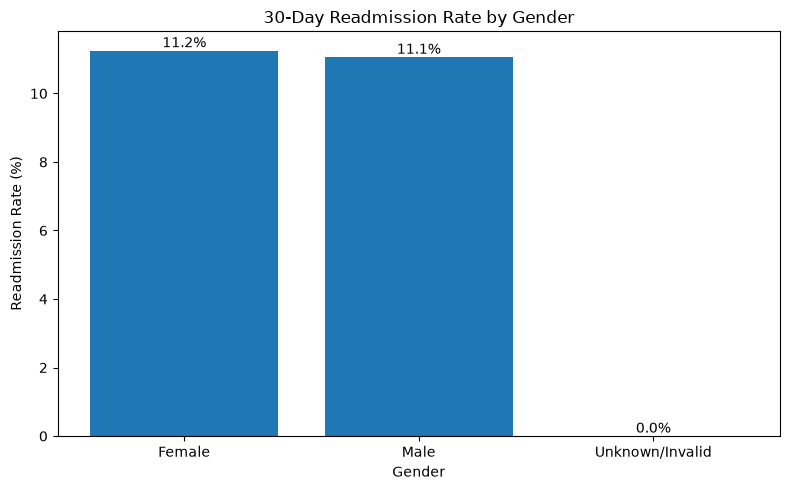


AGE ANALYSIS


,count,readmission_rate
age_group,,
0-10,0,NaN
10-20,0,NaN
20-30,0,NaN
30-40,0,NaN
40-50,0,NaN
50-60,0,NaN
60-70,0,NaN
70-80,0,NaN
80-90,0,NaN


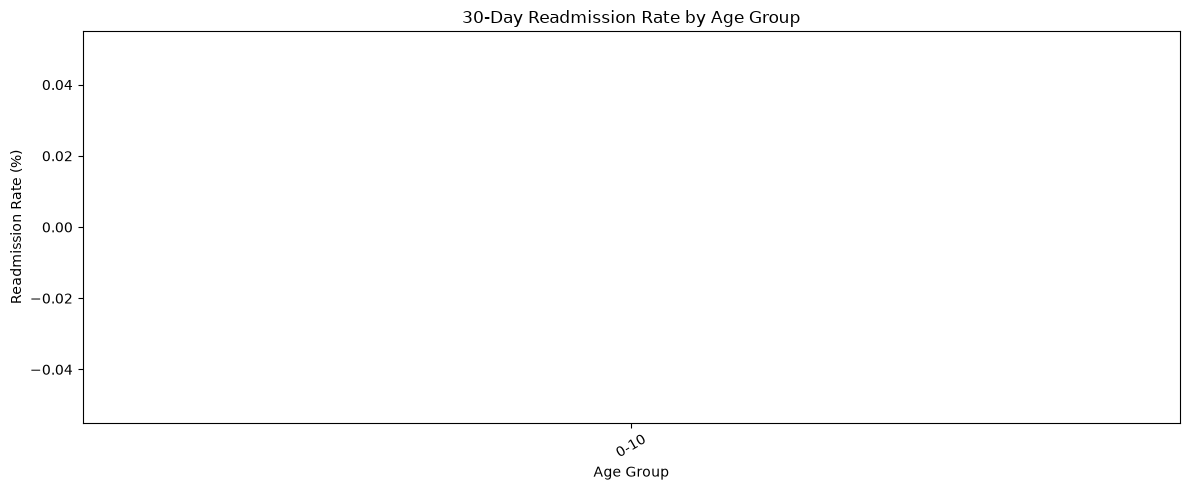


DIABETES MEDICATION ANALYSIS


,count,readmission_rate
diabetesMed,,
No,23403,9.60
Yes,78363,11.63


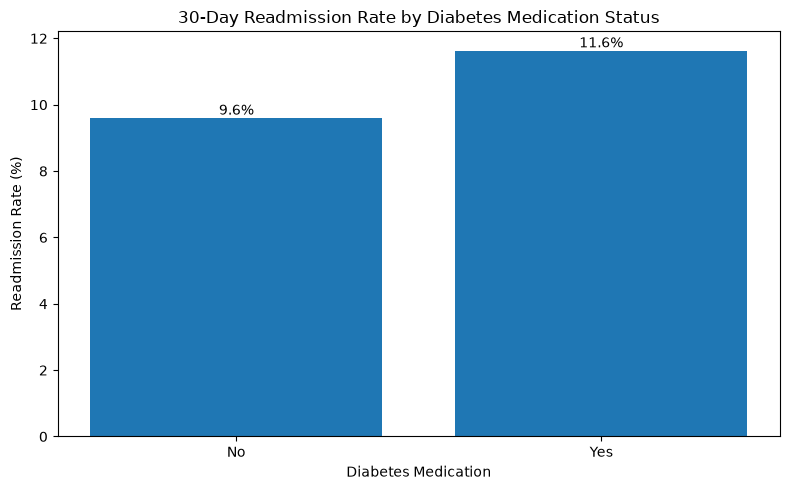


MEDICATION BURDEN ANALYSIS


,count,readmission_rate
medication_group,,
1-5,5066,7.48
6-10,20795,9.45
11-15,29384,10.91
16-20,22641,12.17
21-30,18643,12.87
31+,5237,12.43


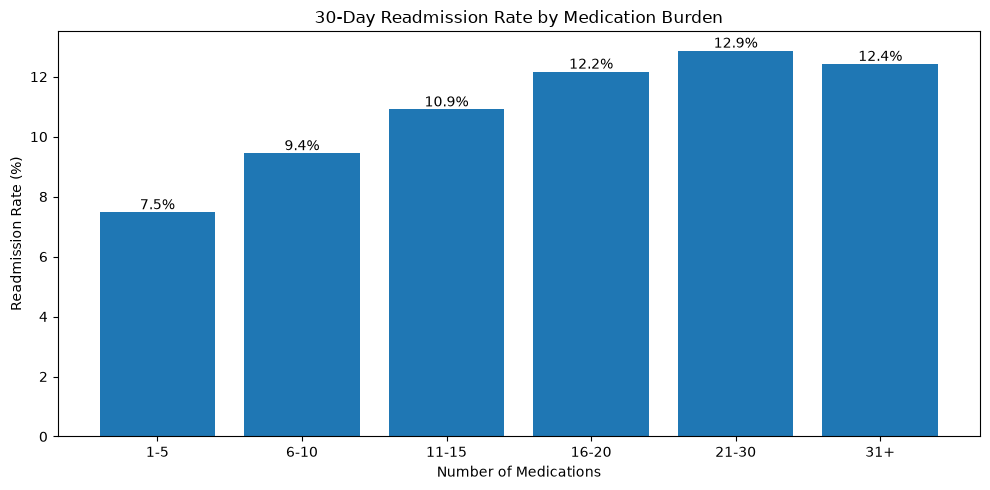


NUMBER OF DIAGNOSES ANALYSIS


,count,readmission_rate
number_diagnoses,,
1,219,5.94
2,1023,6.06
3,2835,7.37
4,5537,8.25
5,11393,9.15
6,10161,10.41
7,10393,10.77
8,10616,11.81
9,49474,12.38


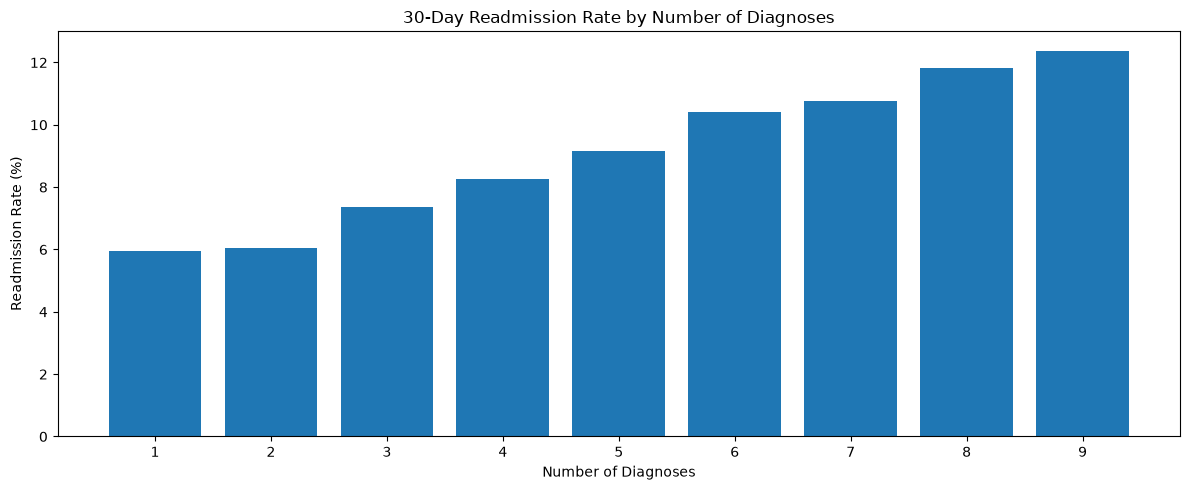


ADMISSION TYPE ANALYSIS


,count,readmission_rate
admission_type_id,,
1,53990,11.52
2,18480,11.18
6,5291,11.08
3,18869,10.39
5,4785,10.34
4,10,10.00
8,320,8.44
7,21,0.00



ADMISSION SOURCE ANALYSIS


,count,readmission_rate
admission_source_id,,
3,187,15.51
20,161,13.66
5,855,11.81
7,57494,11.69
1,29565,10.59
17,6781,10.41
9,125,10.40
2,1104,10.05
4,3187,9.70


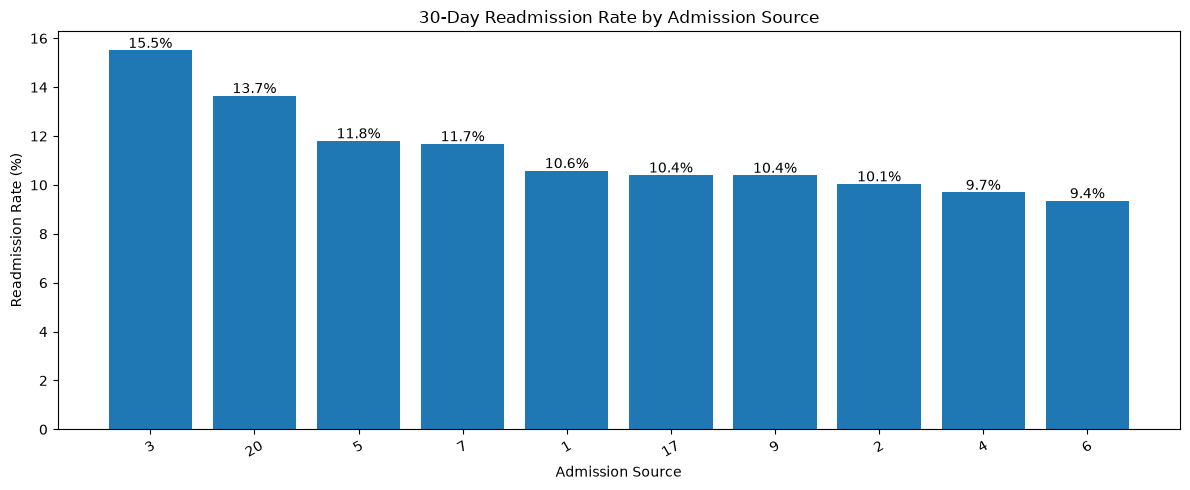


DISCHARGE DISPOSITION ANALYSIS


,count,readmission_rate
discharge_disposition_id,,
28,139,36.69
22,1993,27.70
5,1184,20.86
2,2128,16.07
3,13954,14.66
7,623,14.45
8,108,13.89
4,815,12.76
6,12902,12.70


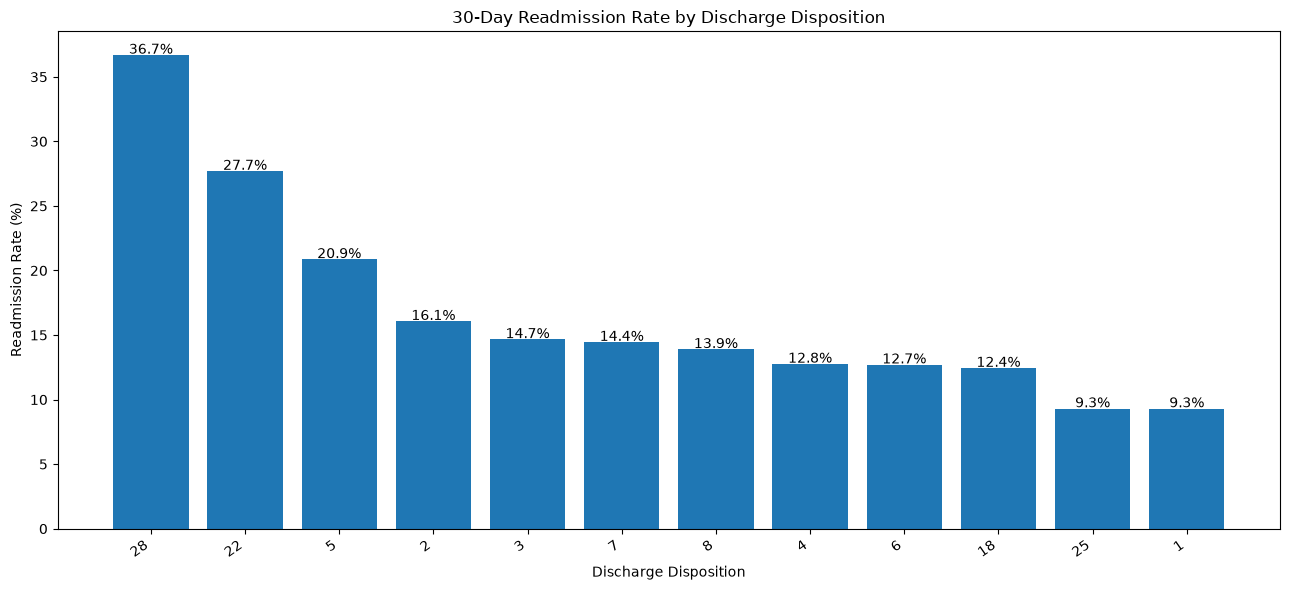


NUMERICAL VARIABLES VS READMISSION


,variable,mean_no_readmission,mean_readmission,difference
0,time_in_hospital,4.35,4.77,0.42
1,num_lab_procedures,42.95,44.23,1.27
2,num_procedures,1.35,1.28,-0.07
3,num_medications,15.91,16.90,0.99
4,number_outpatient,0.36,0.44,0.08
5,number_emergency,0.18,0.36,0.18
6,number_inpatient,0.56,1.22,0.66
7,number_diagnoses,7.39,7.69,0.30



PREVIOUS HEALTHCARE UTILIZATION


,No_Readmission,Readmission,difference
number_outpatient,0.36,0.44,0.08
number_emergency,0.18,0.36,0.18
number_inpatient,0.56,1.22,0.66



NUMERICAL CORRELATION WITH 30-DAY READMISSION


,correlation
number_inpatient,0.165
number_emergency,0.061
number_diagnoses,0.050
time_in_hospital,0.044
num_medications,0.038
num_lab_procedures,0.020
number_outpatient,0.019
num_procedures,-0.012



MISSING VALUES


,missing_count,missing_percent
age,101766,100.0
age_group,101766,100.0



EDA COMPLETED

Key areas analyzed:

1. Overall 30-day readmission rate
2. Gender
3. Age groups
4. Diabetes medication status
5. Medication burden
6. Number of diagnoses
7. Admission type
8. Admission source
9. Discharge disposition
10. Hospital utilization
11. Important numerical variables
12. Numerical correlation with readmission
13. Missing values

Next step:
Feature Engineering -> Train/Test Split -> Model Building



In [61]:
# ============================================================
# COMBINED EDA - FACTORS ASSOCIATED WITH 30-DAY READMISSION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. BASIC SETUP
# ------------------------------------------------------------

TARGET = "readmitted_30"

print("=" * 70)
print("COMBINED EDA - 30-DAY READMISSION")
print("=" * 70)

print(f"\nDataset shape: {df.shape}")

# Check target
print("\nTarget distribution:")
display(
    df[TARGET]
    .value_counts(dropna=False)
    .to_frame("count")
)

print("\nTarget percentage:")
display(
    (df[TARGET].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("percentage")
)


# ============================================================
# 2. GENDER ANALYSIS
# ============================================================

if "gender" in df.columns:

    print("\n" + "=" * 70)
    print("GENDER ANALYSIS")
    print("=" * 70)

    gender_analysis = (
        df.groupby("gender", observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    gender_analysis["readmission_rate"] = (
        gender_analysis["mean"] * 100
    )

    gender_analysis = gender_analysis[
        ["count", "readmission_rate"]
    ].round(2)

    display(gender_analysis)

    plt.figure(figsize=(8, 5))

    bars = plt.bar(
        gender_analysis.index.astype(str),
        gender_analysis["readmission_rate"]
    )

    plt.title("30-Day Readmission Rate by Gender")
    plt.xlabel("Gender")
    plt.ylabel("Readmission Rate (%)")

    for bar, value in zip(
        bars,
        gender_analysis["readmission_rate"]
    ):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            f"{value:.1f}%",
            ha="center"
        )

    plt.tight_layout()
    plt.show()


# ============================================================
# 3. AGE ANALYSIS
# ============================================================

if "age" in df.columns:

    print("\n" + "=" * 70)
    print("AGE ANALYSIS")
    print("=" * 70)

    age_bins = [-np.inf, 10, 20, 30, 40, 50,
                60, 70, 80, 90, np.inf]

    age_labels = [
        "0-10",
        "10-20",
        "20-30",
        "30-40",
        "40-50",
        "50-60",
        "60-70",
        "70-80",
        "80-90",
        "90+"
    ]

    # Remove previous age_group if it exists
    if "age_group" in df.columns:
        df = df.drop(columns=["age_group"])

    df["age_group"] = pd.cut(
        df["age"],
        bins=age_bins,
        labels=age_labels,
        right=False
    )

    age_analysis = (
        df.groupby("age_group", observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    age_analysis["readmission_rate"] = (
        age_analysis["mean"] * 100
    )

    age_analysis = age_analysis[
        ["count", "readmission_rate"]
    ].round(2)

    display(age_analysis)

    plt.figure(figsize=(12, 5))

    bars = plt.bar(
        age_analysis.index.astype(str),
        age_analysis["readmission_rate"]
    )

    plt.title("30-Day Readmission Rate by Age Group")
    plt.xlabel("Age Group")
    plt.ylabel("Readmission Rate (%)")

    for bar, value in zip(
        bars,
        age_analysis["readmission_rate"]
    ):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            f"{value:.1f}%",
            ha="center"
        )

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


# ============================================================
# 4. DIABETES MEDICATION ANALYSIS
# ============================================================

if "diabetesMed" in df.columns:

    print("\n" + "=" * 70)
    print("DIABETES MEDICATION ANALYSIS")
    print("=" * 70)

    diabetes_analysis = (
        df.groupby("diabetesMed", observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    diabetes_analysis["readmission_rate"] = (
        diabetes_analysis["mean"] * 100
    )

    diabetes_analysis = diabetes_analysis[
        ["count", "readmission_rate"]
    ].round(2)

    display(diabetes_analysis)

    plt.figure(figsize=(8, 5))

    bars = plt.bar(
        diabetes_analysis.index.astype(str),
        diabetes_analysis["readmission_rate"]
    )

    plt.title("30-Day Readmission Rate by Diabetes Medication Status")
    plt.xlabel("Diabetes Medication")
    plt.ylabel("Readmission Rate (%)")

    for bar, value in zip(
        bars,
        diabetes_analysis["readmission_rate"]
    ):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            f"{value:.1f}%",
            ha="center"
        )

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. NUMBER OF MEDICATIONS
# ============================================================

if "num_medications" in df.columns:

    print("\n" + "=" * 70)
    print("MEDICATION BURDEN ANALYSIS")
    print("=" * 70)

    medication_bins = [0, 5, 10, 15, 20, 30, np.inf]

    medication_labels = [
        "1-5",
        "6-10",
        "11-15",
        "16-20",
        "21-30",
        "31+"
    ]

    if "medication_group" in df.columns:
        df = df.drop(columns=["medication_group"])

    df["medication_group"] = pd.cut(
        df["num_medications"],
        bins=medication_bins,
        labels=medication_labels,
        include_lowest=True
    )

    medication_analysis = (
        df.groupby("medication_group", observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    medication_analysis["readmission_rate"] = (
        medication_analysis["mean"] * 100
    )

    medication_analysis = medication_analysis[
        ["count", "readmission_rate"]
    ].round(2)

    display(medication_analysis)

    plt.figure(figsize=(10, 5))

    bars = plt.bar(
        medication_analysis.index.astype(str),
        medication_analysis["readmission_rate"]
    )

    plt.title("30-Day Readmission Rate by Medication Burden")
    plt.xlabel("Number of Medications")
    plt.ylabel("Readmission Rate (%)")

    for bar, value in zip(
        bars,
        medication_analysis["readmission_rate"]
    ):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            f"{value:.1f}%",
            ha="center"
        )

    plt.tight_layout()
    plt.show()


# ============================================================
# 6. NUMBER OF DIAGNOSES
# ============================================================

if "number_diagnoses" in df.columns:

    print("\n" + "=" * 70)
    print("NUMBER OF DIAGNOSES ANALYSIS")
    print("=" * 70)

    diagnosis_analysis = (
        df.groupby("number_diagnoses", observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    diagnosis_analysis["readmission_rate"] = (
        diagnosis_analysis["mean"] * 100
    )

    diagnosis_analysis = diagnosis_analysis[
        ["count", "readmission_rate"]
    ].round(2)

    display(diagnosis_analysis)

    # Use only diagnosis groups with reasonable sample size
    diagnosis_plot = diagnosis_analysis[
        diagnosis_analysis["count"] >= 100
    ].copy()

    plt.figure(figsize=(12, 5))

    plt.bar(
        diagnosis_plot.index.astype(str),
        diagnosis_plot["readmission_rate"]
    )

    plt.title(
        "30-Day Readmission Rate by Number of Diagnoses"
    )
    plt.xlabel("Number of Diagnoses")
    plt.ylabel("Readmission Rate (%)")

    plt.tight_layout()
    plt.show()


# ============================================================
# 7. ADMISSION TYPE
# ============================================================

if "admission_type_id" in df.columns:

    print("\n" + "=" * 70)
    print("ADMISSION TYPE ANALYSIS")
    print("=" * 70)

    admission_analysis = (
        df.groupby("admission_type_id", observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    admission_analysis["readmission_rate"] = (
        admission_analysis["mean"] * 100
    )

    admission_analysis = admission_analysis[
        ["count", "readmission_rate"]
    ].sort_values(
        "readmission_rate",
        ascending=False
    ).round(2)

    display(admission_analysis)


# ============================================================
# 8. ADMISSION SOURCE
# ============================================================

if "admission_source_id" in df.columns:

    print("\n" + "=" * 70)
    print("ADMISSION SOURCE ANALYSIS")
    print("=" * 70)

    source_analysis = (
        df.groupby("admission_source_id", observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    source_analysis["readmission_rate"] = (
        source_analysis["mean"] * 100
    )

    source_analysis = source_analysis[
        ["count", "readmission_rate"]
    ]

    # Ignore extremely small groups
    source_plot = source_analysis[
        source_analysis["count"] >= 100
    ].sort_values(
        "readmission_rate",
        ascending=False
    ).head(10).round(2)

    display(source_plot)

    plt.figure(figsize=(12, 5))

    bars = plt.bar(
        source_plot.index.astype(str),
        source_plot["readmission_rate"]
    )

    plt.title(
        "30-Day Readmission Rate by Admission Source"
    )
    plt.xlabel("Admission Source")
    plt.ylabel("Readmission Rate (%)")

    for bar, value in zip(
        bars,
        source_plot["readmission_rate"]
    ):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            f"{value:.1f}%",
            ha="center"
        )

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


# ============================================================
# 9. DISCHARGE DISPOSITION
# ============================================================

if "discharge_disposition_id" in df.columns:

    print("\n" + "=" * 70)
    print("DISCHARGE DISPOSITION ANALYSIS")
    print("=" * 70)

    discharge_analysis = (
        df.groupby("discharge_disposition_id", observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    discharge_analysis["readmission_rate"] = (
        discharge_analysis["mean"] * 100
    )

    discharge_analysis = discharge_analysis[
        ["count", "readmission_rate"]
    ]

    # Remove tiny groups because their rates can be misleading
    discharge_plot = discharge_analysis[
        discharge_analysis["count"] >= 100
    ].sort_values(
        "readmission_rate",
        ascending=False
    ).head(12).round(2)

    display(discharge_plot)

    plt.figure(figsize=(13, 6))

    bars = plt.bar(
        discharge_plot.index.astype(str),
        discharge_plot["readmission_rate"]
    )

    plt.title(
        "30-Day Readmission Rate by Discharge Disposition"
    )
    plt.xlabel("Discharge Disposition")
    plt.ylabel("Readmission Rate (%)")

    for bar, value in zip(
        bars,
        discharge_plot["readmission_rate"]
    ):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            f"{value:.1f}%",
            ha="center"
        )

    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


# ============================================================
# 10. IMPORTANT NUMERICAL VARIABLES
# ============================================================

numeric_candidates = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

available_numeric = [
    col for col in numeric_candidates
    if col in df.columns
]

print("\n" + "=" * 70)
print("NUMERICAL VARIABLES VS READMISSION")
print("=" * 70)

numeric_summary = []

for col in available_numeric:

    no_readmission = df.loc[
        df[TARGET] == 0, col
    ].mean()

    readmission = df.loc[
        df[TARGET] == 1, col
    ].mean()

    numeric_summary.append({
        "variable": col,
        "mean_no_readmission": no_readmission,
        "mean_readmission": readmission,
        "difference": readmission - no_readmission
    })

numeric_summary = pd.DataFrame(numeric_summary)

display(
    numeric_summary.round(2)
)


# ============================================================
# 11. READMISSION VS PRIOR UTILIZATION
# ============================================================

utilization_cols = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

available_utilization = [
    col for col in utilization_cols
    if col in df.columns
]

if available_utilization:

    print("\n" + "=" * 70)
    print("PREVIOUS HEALTHCARE UTILIZATION")
    print("=" * 70)

    utilization_summary = (
        df.groupby(TARGET)[available_utilization]
        .mean()
        .T
    )

    utilization_summary.columns = [
        "No_Readmission",
        "Readmission"
    ]

    utilization_summary["difference"] = (
        utilization_summary["Readmission"]
        - utilization_summary["No_Readmission"]
    )

    display(utilization_summary.round(2))


# ============================================================
# 12. OVERALL CORRELATION WITH READMISSION
# ============================================================

print("\n" + "=" * 70)
print("NUMERICAL CORRELATION WITH 30-DAY READMISSION")
print("=" * 70)

correlation_cols = [
    col for col in available_numeric
    if pd.api.types.is_numeric_dtype(df[col])
]

if correlation_cols:

    correlation = (
        df[correlation_cols + [TARGET]]
        .corr(numeric_only=True)[TARGET]
        .drop(TARGET)
        .sort_values(
            key=abs,
            ascending=False
        )
    )

    display(
        correlation.to_frame("correlation")
        .round(3)
    )


# ============================================================
# 13. MISSING VALUE CHECK
# ============================================================

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

missing = (
    df.isnull()
    .sum()
    .to_frame("missing_count")
)

missing["missing_percent"] = (
    missing["missing_count"]
    / len(df) * 100
)

missing = missing[
    missing["missing_count"] > 0
].sort_values(
    "missing_percent",
    ascending=False
)

if len(missing) > 0:
    display(missing.round(2))
else:
    print("No missing values found.")


# ============================================================
# 14. FINAL EDA SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("EDA COMPLETED")
print("=" * 70)

print("""
Key areas analyzed:

1. Overall 30-day readmission rate
2. Gender
3. Age groups
4. Diabetes medication status
5. Medication burden
6. Number of diagnoses
7. Admission type
8. Admission source
9. Discharge disposition
10. Hospital utilization
11. Important numerical variables
12. Numerical correlation with readmission
13. Missing values

Next step:
Feature Engineering -> Train/Test Split -> Model Building
""")

In [62]:
print(df["age"].head(10))
print(df["age"].dtype)
print(df["age"].isna().sum())

0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
5   NaN
6   NaN
7   NaN
8   NaN
9   NaN
Name: age, dtype: float64
float64
101766


In [54]:
# ============================================================
# AGE GROUP ANALYSIS
# ============================================================

age_analysis = (
    df.groupby("age", observed=False)["readmitted_30"]
      .agg(["count", "mean"])
)

age_analysis["readmission_rate"] = (
    age_analysis["mean"] * 100
)

age_analysis = age_analysis[
    ["count", "readmission_rate"]
].round(2)

display(age_analysis)

,count,readmission_rate
age,,
[0-10),161,1.86
[10-20),691,5.79
[20-30),1657,14.24
[30-40),3775,11.23
[40-50),9685,10.60
[50-60),17256,9.67
[60-70),22483,11.13
[70-80),26068,11.77
[80-90),17197,12.08


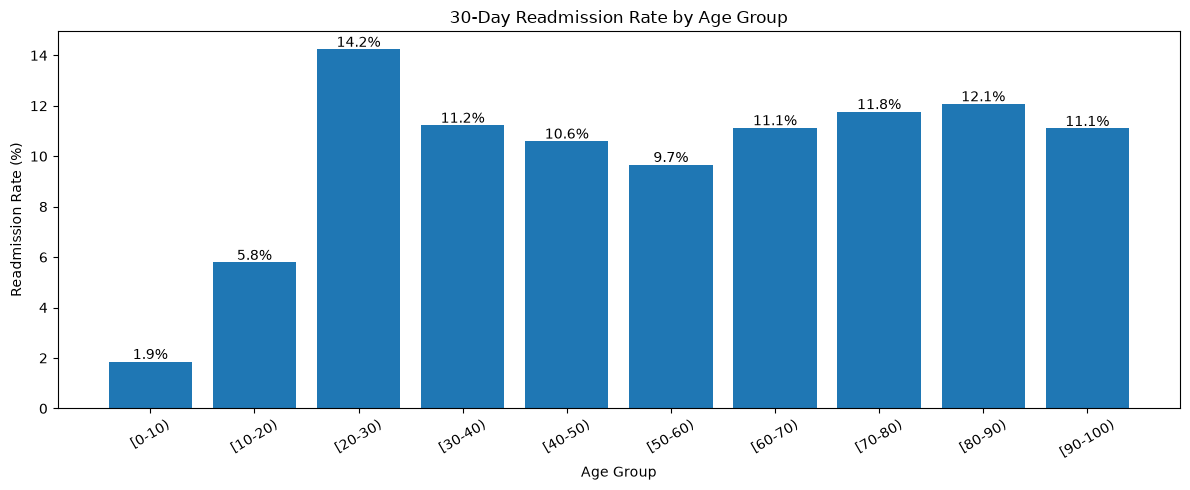

In [55]:
plt.figure(figsize=(12, 5))

bars = plt.bar(
    age_analysis.index.astype(str),
    age_analysis["readmission_rate"]
)

plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")

for bar, value in zip(
    bars,
    age_analysis["readmission_rate"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.1f}%",
        ha="center"
    )

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# FINAL EDA - STATISTICAL & RISK SUMMARY
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TARGET = "readmitted_30"

print("=" * 70)
print("FINAL EDA SUMMARY")
print("=" * 70)


# ------------------------------------------------------------
# 1. OVERALL READMISSION RATE
# ------------------------------------------------------------

overall_rate = df[TARGET].mean() * 100

print(f"\nOverall 30-Day Readmission Rate: {overall_rate:.2f}%")
print(f"Total Patients: {len(df):,}")


# ------------------------------------------------------------
# 2. CATEGORICAL VARIABLE SUMMARY
# ------------------------------------------------------------

categorical_features = [
    "gender",
    "age",
    "diabetesMed",
    "admission_type_id",
    "admission_source_id",
    "discharge_disposition_id"
]

available_categorical = [
    col for col in categorical_features
    if col in df.columns
]

print("\n" + "=" * 70)
print("CATEGORICAL FEATURE SUMMARY")
print("=" * 70)

for col in available_categorical:

    summary = (
        df.groupby(col, observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    summary["readmission_rate"] = summary["mean"] * 100

    summary = summary[
        ["count", "readmission_rate"]
    ].sort_values(
        "readmission_rate",
        ascending=False
    )

    print(f"\n--- {col} ---")

    # Only show groups with at least 100 patients
    display(
        summary[summary["count"] >= 100]
        .round(2)
    )


# ------------------------------------------------------------
# 3. NUMERICAL FEATURE SUMMARY
# ------------------------------------------------------------

numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

available_numeric = [
    col for col in numeric_features
    if col in df.columns
]

print("\n" + "=" * 70)
print("NUMERICAL FEATURES")
print("=" * 70)

numeric_results = []

for col in available_numeric:

    no_readmission = df.loc[
        df[TARGET] == 0, col
    ].mean()

    readmission = df.loc[
        df[TARGET] == 1, col
    ].mean()

    numeric_results.append({
        "feature": col,
        "no_readmission_mean": no_readmission,
        "readmission_mean": readmission,
        "difference": readmission - no_readmission
    })

numeric_results = pd.DataFrame(numeric_results)

display(
    numeric_results
    .sort_values(
        "difference",
        key=abs,
        ascending=False
    )
    .round(2)
)


# ------------------------------------------------------------
# 4. CORRELATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CORRELATION WITH READMISSION")
print("=" * 70)

correlation = (
    df[available_numeric + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(
        key=abs,
        ascending=False
    )
)

display(
    correlation
    .to_frame("correlation")
    .round(3)
)


# ------------------------------------------------------------
# 5. PRIOR HOSPITAL UTILIZATION
# ------------------------------------------------------------

utilization = [
    col for col in [
        "number_outpatient",
        "number_emergency",
        "number_inpatient"
    ]
    if col in df.columns
]

if utilization:

    print("\n" + "=" * 70)
    print("PRIOR HEALTHCARE UTILIZATION")
    print("=" * 70)

    utilization_summary = (
        df.groupby(TARGET)[utilization]
        .mean()
        .T
    )

    utilization_summary.columns = [
        "No_Readmission",
        "Readmission"
    ]

    utilization_summary["Difference"] = (
        utilization_summary["Readmission"]
        - utilization_summary["No_Readmission"]
    )

    display(
        utilization_summary.round(2)
    )


# ------------------------------------------------------------
# 6. HIGH-RISK GROUPS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HIGH-RISK GROUP IDENTIFICATION")
print("=" * 70)

risk_tables = {}

for col in available_categorical:

    table = (
        df.groupby(col, observed=False)[TARGET]
        .agg(["count", "mean"])
    )

    table["readmission_rate"] = table["mean"] * 100

    # Minimum sample size = 100
    table = table[
        table["count"] >= 100
    ]

    table = table.sort_values(
        "readmission_rate",
        ascending=False
    )

    risk_tables[col] = table

    if len(table) > 0:

        highest = table.iloc[0]

        print(
            f"{col}: "
            f"{table.index[0]} → "
            f"{highest['readmission_rate']:.2f}% "
            f"({int(highest['count']):,} patients)"
        )


# ------------------------------------------------------------
# 7. EDA CONCLUSION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EDA CONCLUSION")
print("=" * 70)

print("""
The EDA indicates that 30-day hospital readmission is associated
with multiple patient and hospitalization characteristics.

Important candidate predictors include:

• Age group
• Gender
• Diabetes medication status
• Medication burden
• Number of diagnoses
• Admission type
• Admission source
• Discharge disposition
• Previous inpatient visits
• Previous emergency visits
• Previous outpatient visits
• Hospital stay duration
• Number of procedures
• Number of laboratory procedures

These variables should now be evaluated through statistical testing
and machine-learning models rather than relying only on descriptive
EDA.

NEXT:
Feature Engineering → Train/Test Split → Baseline Model
→ Logistic Regression → Tree-Based Models → Model Comparison
""")

FINAL EDA SUMMARY

Overall 30-Day Readmission Rate: 11.16%
Total Patients: 101,766

CATEGORICAL FEATURE SUMMARY

--- gender ---


,count,readmission_rate
gender,,
Female,54708,11.25
Male,47055,11.06



--- age ---


,count,readmission_rate
age,,
[20-30),1657,14.24
[80-90),17197,12.08
[70-80),26068,11.77
[30-40),3775,11.23
[60-70),22483,11.13
[90-100),2793,11.10
[40-50),9685,10.60
[50-60),17256,9.67
[10-20),691,5.79



--- diabetesMed ---


,count,readmission_rate
diabetesMed,,
Yes,78363,11.63
No,23403,9.60


... (9 outputs left out)

,correlation
number_inpatient,0.165
number_emergency,0.061
number_diagnoses,0.050
time_in_hospital,0.044
num_medications,0.038
num_lab_procedures,0.020
number_outpatient,0.019
num_procedures,-0.012



PRIOR HEALTHCARE UTILIZATION


,No_Readmission,Readmission,Difference
number_outpatient,0.36,0.44,0.08
number_emergency,0.18,0.36,0.18
number_inpatient,0.56,1.22,0.66



HIGH-RISK GROUP IDENTIFICATION
gender: Female → 11.25% (54,708 patients)
age: [20-30) → 14.24% (1,657 patients)
diabetesMed: Yes → 11.63% (78,363 patients)
admission_type_id: 1 → 11.52% (53,990 patients)
admission_source_id: 3 → 15.51% (187 patients)
discharge_disposition_id: 28 → 36.69% (139 patients)

EDA CONCLUSION

The EDA indicates that 30-day hospital readmission is associated
with multiple patient and hospitalization characteristics.

Important candidate predictors include:

• Age group
• Gender
• Diabetes medication status
• Medication burden
• Number of diagnoses
• Admission type
• Admission source
• Discharge disposition
• Previous inpatient visits
• Previous emergency visits
• Previous outpatient visits
• Hospital stay duration
• Number of procedures
• Number of laboratory procedures

These variables should now be evaluated through statistical testing
and machine-learning models rather than relying only on descriptive
EDA.

NEXT:
Feature Engineering → Train/Test Split → Bas